# Mandatory assignment 3

**GitHub repository:** https://github.com/anders-hv/TECH2-assignment3

## About the assignment

- Complete the assignment individually.
- You may use online resources, including generative AI. Include a statement
  explaining how you used AI, or state that you did not use it.

## Submission

- Submit your completed `assignment3.ipynb` on Canvas by
  **October 23, 2026, at 23:59**.

## Submission requirements

- Create a new repository from the template linked on Canvas (click **Use this
  template** > **Create a new repository**) and implement your solution in your
  GitHub repository.
- Use the TECH2 environment from the course.
- Implement your solution directly in this notebook by inserting code and text
  cells. Do not create additional notebooks or files.
- Include all requested numerical results, figures, and short written answers.
- Give each figure a title, label its axes, and include a legend where needed.
- Before you submit, make sure your GitHub repository is **publicly accessible** and include its URL at the
  top of this notebook.
- Before submission, restart the kernel and run all cells in order. Your notebook
  must run without errors and find the CSV without an absolute file path.

## Hints

- Use the material from lectures and workshops 1–3: functions, loops, NumPy,
  pandas, and Matplotlib.
- Compute group statistics using loops; there is no need to use `groupby()`
  (which we cover in lecture 4), but you can do so if you prefer.

***
## Stock market participation in US households

Who participates in the stock market, and how has participation changed over time?
To answer this question, you will analyze data from the
[Survey of Consumer Finances](https://www.federalreserve.gov/econres/scfindex.htm)
(SCF), a representative survey of US households conducted every three years
from 1989 to 2022.

The file `SCF_10pct.csv` contains a 10% sample of the SCF data. The central variables of
interest for this assignment are:

1. `stocks`, which reports the value of directly held stocks (in US dollars); and
2. `equity`, which reports the value of all equity holdings (in US dollars),
   including direct stock ownership and indirect exposure through mutual funds,
   retirement accounts, and other investment vehicles.

We measure stock market participation in two ways:

- **Direct participation:** a household owns individual stocks (`stocks > 0`).
- **Overall participation:** a household holds equity directly or indirectly
  (`equity > 0`).

For each measure, the *participation rate* is the percentage of households
satisfying that condition. We therefore calculate two rates: the **direct
participation rate** and the **overall participation rate**. Direct participants
are included among overall participants, so the two rates should not be added.

## Data description

| Variable | Description |
|----------|-------------|
| `id` | Unique observation identifier |
| `year` | Survey year |
| `age` | Age of the household reference person |
| `educ` | Education level: `1`: No high school; `2`: High school; `3`: Some college; `4`: Bachelor's or higher |
| `stocks` | Value of directly held individual stocks (in US dollars) |
| `equity` | Total directly and indirectly owned stock equity (in US dollars) |

***
## Part 1 — Data preparation

1. Load `SCF_10pct.csv` into a pandas DataFrame. Print the columns contained in
   the DataFrame and their number of non-missing values.
2. Drop all observations that have missing values for any of the variables listed
   in the table above. For each variable, report how many observations you dropped
   and how many remain.
3. Keep observations with `25 <= age <= 89`, including both endpoints.
   Report how many observations you dropped and how many remain.
4. Create two 0/1 indicator columns:
   - `direct`: 1 if the household participates directly (`stocks > 0`),
     0 otherwise.
   - `overall`: 1 if the household participates directly or indirectly
     (`equity > 0`), 0 otherwise.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:
df = pd.read_csv("SCF_10pct.csv")

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5808 entries, 0 to 5807
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   id      5808 non-null   int64  
 1   year    5808 non-null   int64  
 2   age     5808 non-null   int64  
 3   educ    5792 non-null   float64
 4   stocks  5790 non-null   float64
 5   equity  5792 non-null   float64
dtypes: float64(3), int64(3)
memory usage: 272.4 KB


In [3]:
for col in df.columns:
    rows_before = len(df)
    df = df[df[col].notna()]
    rows_after = len(df)
    print(f"{col}: dropped {rows_before - rows_after}, remaining {rows_after}")

id: dropped 0, remaining 5808
year: dropped 0, remaining 5808
age: dropped 0, remaining 5808
educ: dropped 16, remaining 5792
stocks: dropped 18, remaining 5774
equity: dropped 16, remaining 5758


In [4]:
rows_before = len(df)
df = df[(df["age"] >= 25) & (df["age"] <= 89)]
rows_after = len(df)
print(f"Age filter: dropped {rows_before - rows_after}, remaining {rows_after}")

Age filter: dropped 326, remaining 5432


In [5]:
df["direct"] = (df["stocks"] > 0).astype(int)
df["overall"] = (df["equity"] > 0).astype(int)

***
## Part 2 — Participation rates

You are now ready to compute the stock market participation rates for the
final sample. You will compute these in two ways: first, by writing a function
that uses a loop to compute the participation rate, and second, by using pandas's
built-in `mean()` method.

1. Write a function `participation_rate(indicator)` that takes a nonempty
   one-dimensional sequence of 0/1 values and returns the fraction of ones
   (in percent).
2. Apply your function to the final sample's `direct` and `overall`
   columns to compute the direct and overall participation rates. Report the
   results.
3. Use pandas's built-in `mean()` method to compute the direct and overall
   participation rates. Report the results.

In [6]:
def participation_rate(indicator):
    count = 0
    for value in indicator:
        if value == 1:
            count += 1
    fraction = count / len(indicator)
    percentage = fraction * 100
    return percentage

In [7]:
direct_rate = participation_rate(df["direct"])
overall_rate = participation_rate(df["overall"])

print(f"Direct stock market participation: {direct_rate:.1f}%")
print(f"Overall stock market participation: {overall_rate:.1f}%")

Direct stock market participation: 17.0%
Overall stock market participation: 49.4%


In [8]:
direct_avg = (df["direct"].mean()) * 100
overall_avg = (df["overall"].mean()) * 100

print(f"Direct stock market participation: {direct_avg:.1f}%")
print(f"Overall stock market participation: {overall_avg:.1f}%")

Direct stock market participation: 17.0%
Overall stock market participation: 49.4%


***
## Part 3 — Participation by education

1. Loop over education categories 1–4. For each category, calculate the direct
   participation rate and the overall participation rate (in percent).
2. Display the results, rounding rates to one decimal place.
3. Create a figure with two subplots, one for each rate, containing bar charts
   of participation rates across education categories.
4. In two or three sentences, describe the education pattern.

In [9]:
direct_rates3 = []
overall_rates3 = []

for edu in [1, 2, 3, 4]:
    subset = df[df['educ'] == edu]
    direct = subset['direct'].mean() * 100
    overall = subset['overall'].mean() * 100
    direct_rates3.append(direct)
    overall_rates3.append(overall)
    print(f'Education {edu}: Direct participation {direct:.1f}%, Overall participation {overall:.1f}%')

Education 1: Direct participation 4.4%, Overall participation 17.3%
Education 2: Direct participation 11.4%, Overall participation 39.9%
Education 3: Direct participation 13.5%, Overall participation 48.3%
Education 4: Direct participation 30.5%, Overall participation 73.5%


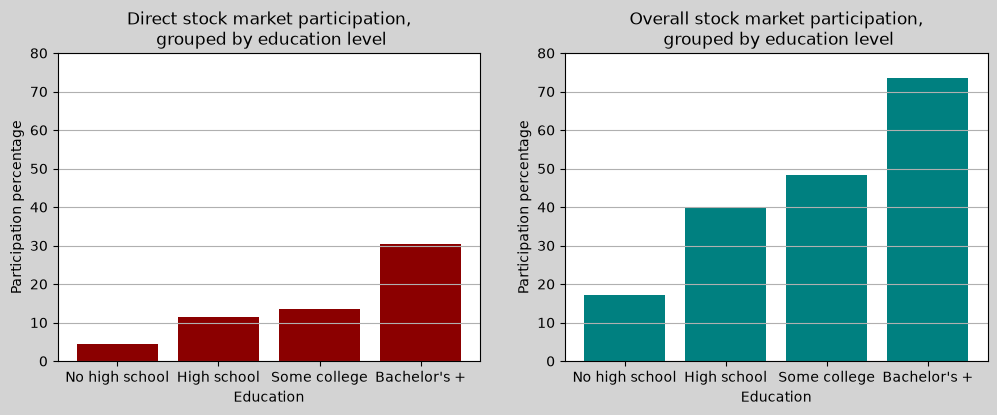

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), facecolor='lightgrey')
edu_labels = ["No high school", "High school", "Some college", "Bachelor's +"]

axes[0].bar(edu_labels, direct_rates3, color="darkred")
axes[0].set_ylim(0, 80)
axes[0].set_title("Direct stock market participation,\n grouped by education level")
axes[0].set_xlabel("Education")
axes[0].set_ylabel("Participation percentage")
axes[0].grid(axis='y')

axes[1].bar(edu_labels, overall_rates3, color="teal")
axes[1].set_ylim(0, 80)
axes[1].set_title("Overall stock market participation,\n grouped by education level")
axes[1].set_xlabel("Education")
axes[1].set_ylabel("Participation percentage")
axes[1].grid(axis="y")
plt.show()

### Reflection on education pattern ###

Participation increases with education, only 4.4% of households without high school education hold stocks directly, compared to 30.5% among the ones with a Bachelor's degree or higher (nearly 7 times higher), and for overall participation the two groups score 17.3% vs 73.5% (about 4 times higher).

Looking at direct participation, the largest jump happens between “Some college” and “Bachelor’s +” (about 17 percentage points), while for overall participation the biggest jump is between “No high school” and “High school”. This could suggest that direct stock ownership is more concentrated among Bachelor's+ graduates, while indirect ownership (e.g. funds and pension savings) are spread a bit more evenly.


***
## Part 4 — Participation over time

1. Loop over years. For each year, compute the direct participation rate and the
   overall participation rate.
2. Create a line plot showing both participation rates over time in a single figure.
3. Report the changes from 1989 to 2022 in the direct and overall participation
   rates, both in percentage points.
4. Describe the main time patterns in two or three sentences.

In [11]:
years = np.arange(1989, 2023, 3)

direct_rates4 = []
overall_rates4 = []

for y in years:
    subset = df[df['year'] == y]
    direct = subset['direct'].mean() * 100
    overall = subset['overall'].mean() * 100
    direct_rates4.append(direct)
    overall_rates4.append(overall)
    print(f'{y}: Direct participation {direct:.1f}%, Overall participation {overall:.1f}%')

1989: Direct participation 15.6%, Overall participation 31.6%
1992: Direct participation 18.3%, Overall participation 40.1%
1995: Direct participation 15.7%, Overall participation 45.9%
1998: Direct participation 19.9%, Overall participation 51.2%
2001: Direct participation 21.8%, Overall participation 57.0%
2004: Direct participation 18.9%, Overall participation 54.7%
2007: Direct participation 17.3%, Overall participation 56.5%
2010: Direct participation 17.4%, Overall participation 50.3%
2013: Direct participation 14.8%, Overall participation 49.9%
2016: Direct participation 12.3%, Overall participation 52.0%
2019: Direct participation 12.4%, Overall participation 49.8%
2022: Direct participation 19.2%, Overall participation 54.3%


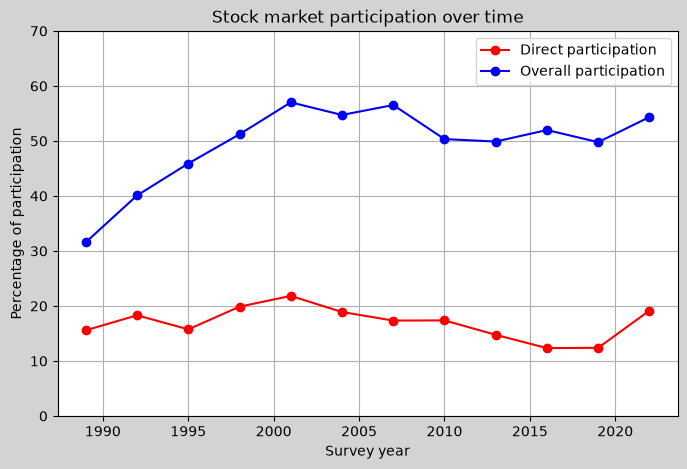

In [12]:
fig, ax = plt.subplots(figsize=(8, 5), facecolor='lightgrey')

xvalues = years
yvalues1 = direct_rates4
yvalues2 = overall_rates4

ax.plot(xvalues, yvalues1, color='red', marker='o', label='Direct participation')
ax.plot(xvalues, yvalues2, color='blue', marker='o', label='Overall participation')
ax.set_title('Stock market participation over time')
ax.set_ylim(0, 70)
ax.set_xlabel('Survey year')
ax.set_ylabel('Percentage of participation')
ax.legend()
ax.grid()

In [13]:
direct_change = direct_rates4[-1] - direct_rates4[0]
overall_change = overall_rates4[-1] - overall_rates4[0]

print(f'Change in direct participation from 1989-2022: {direct_change:.1f} percentage points')
print(f'Change in overall participation from 1989-2022: {overall_change:.1f} percentage points')


Change in direct participation from 1989-2022: 3.6 percentage points
Change in overall participation from 1989-2022: 22.8 percentage points


### Reflection on time patterns ###
Overall participation increased steadily from 1989 to about 2001, and then levelled off at around 50-55%. Direct participation however, moved up and down, seemingly without ant long-term trend, hitting a low in 2016-2019. As the numbers and chart above shows, the growth in overall participation since 1989 came almost entirely from indirect ownership, as overall participation increased by 22.8 percentage points, vs. only 3.6 percentage points increase in direct participation.  

***
## AI-use statement

I used Claude to help explain some of the concepts and methods from the lectures, that were relevant for the assignment. I also used it to help me find bugs in the code I had written, as well as for help on visuals, such as what functions to use for adding background color and a grid to my charts. When stuck with bugs, AI sometimes suggested lines of code or ways to restructure. Before using any of the suggestions however, I always completed, adapted and tested the lines myself, both to make sure that the output was correct, and to make sure that I had a proper understanding of how it works. Except for those suggestions however, the code itself and the reflection parts were written by myself. 